In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, header=None, names=cols)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print(df.shape)
print(df.describe())
print(df["Outcome"].value_counts())   # 0 = no diabetes, 1 = diabetes

(768, 9)
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000         

In [ ]:
# Zero is impossible for these columns, so it really means "missing"
zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df.isnull().sum())
df[zero_cols] = df[zero_cols].fillna(df[zero_cols].median())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


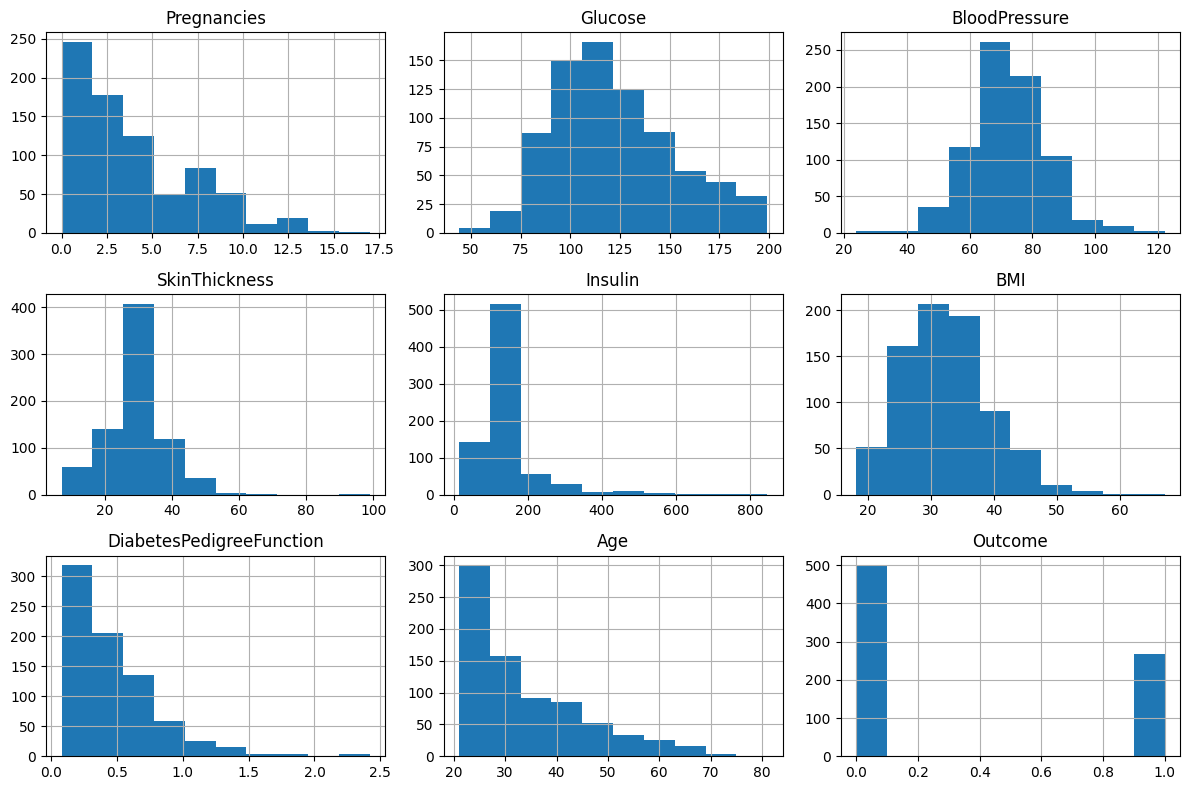

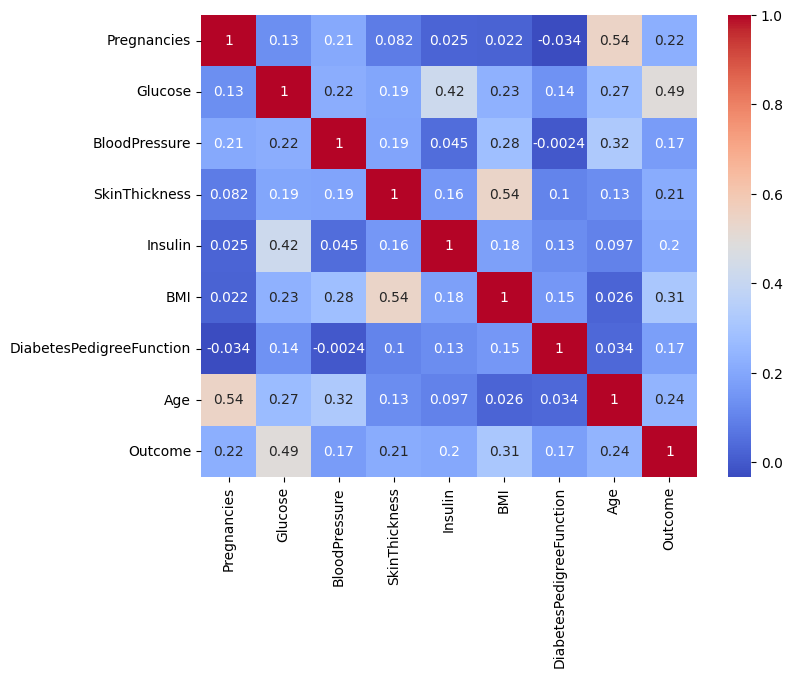

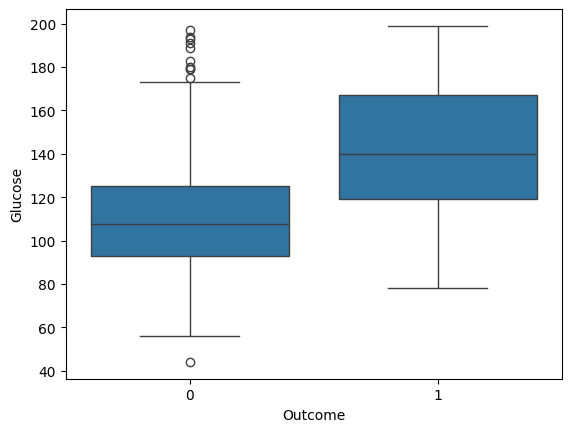

In [ ]:
df.hist(figsize=(12,8)); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

sns.boxplot(x="Outcome", y="Glucose", data=df); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    results.append([name, accuracy_score(y_test,p), precision_score(y_test,p),
                    recall_score(y_test,p), f1_score(y_test,p)])

pd.DataFrame(results, columns=["Model","Accuracy","Precision","Recall","F1"]).round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.708,0.600,0.500,0.545
1,Decision Tree,0.786,0.698,0.685,0.692
2,Random Forest,0.740,0.652,0.556,0.600


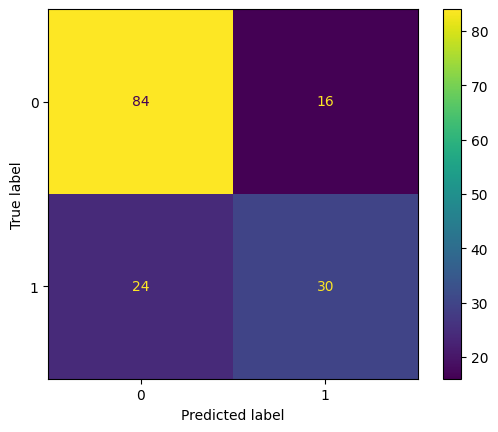

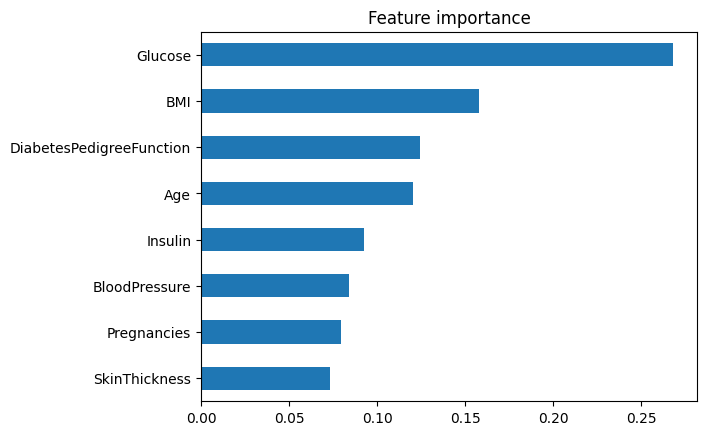

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

rf = models["Random Forest"]
ConfusionMatrixDisplay.from_estimator(rf, X_test_s, y_test); plt.show()

pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind="barh")
plt.title("Feature importance"); plt.show()

In [ ]:
import joblib
joblib.dump(rf, "model.pkl")
joblib.dump(scaler, "scaler.pkl")

from google.colab import files
files.download("model.pkl"); files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X_train_s, y_train, cv=5, scoring="recall")
    print(f"{name}: recall = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: recall = 0.584 (+/- 0.060)
Decision Tree: recall = 0.570 (+/- 0.086)
Random Forest: recall = 0.584 (+/- 0.053)


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 8, None],
    "min_samples_split": [2, 5, 10],
}
grid = GridSearchCV(RandomForestClassifier(random_state=42, class_weight="balanced"),
                    param_grid, cv=5, scoring="recall", n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Best settings:", grid.best_params_)
best_rf = grid.best_estimator_
p = best_rf.predict(X_test_s)
print("Accuracy :", round(accuracy_score(y_test, p), 3))
print("Precision:", round(precision_score(y_test, p), 3))
print("Recall   :", round(recall_score(y_test, p), 3))
print("F1       :", round(f1_score(y_test, p), 3))

Best settings: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 300}
Accuracy : 0.747
Precision: 0.615
Recall   : 0.741
F1       : 0.672
